# Tutorial 10: 4D-Var, Part 2. Tangent-Linear and Adjoint Models

*Part 2 of 5.  Previous: [Tutorial 9, cost function and linear case](09_4DVar_cost_function_and_linear_case.ipynb).  Next: [Tutorial 11, twin experiment and window length](11_4DVar_twin_experiment_and_window_length.ipynb).*

**Question.** In Part 1 the model was a matrix, so $J$ was a quadratic with a closed-form minimiser. Real models are nonlinear. To minimise $J$ iteratively we need its gradient with respect to the initial state, which can have millions of components. How do we get it cheaply and *exactly*?

**You will learn**

- the Lorenz-63 test model and why it is a good proxy for weather;
- the tangent-linear model (TLM), the Jacobian of the time-stepping scheme;
- the discrete adjoint: the transposed TLM run **backwards in time**, driven by the observation misfits;
- three tests every adjoint must pass: dot-product test, Taylor test, finite-difference gradient check;
- why the cost of the gradient does not depend on the number of unknowns.

This builds on the adjoint ideas of Tutorials 5 and 8. ~20 minutes, NumPy and Matplotlib only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})

## 1. The model: Lorenz-63

$$\dot x=\sigma(y-x),\qquad \dot y=x(\rho-z)-y,\qquad \dot z=xy-\beta z,\qquad(\sigma,\rho,\beta)=(10,28,\tfrac83).$$

Three variables, yet chaotic: nearby trajectories separate roughly like $e^{0.9\,t}$. Like the atmosphere, small errors in the initial state grow, so the initial condition must be estimated well, and that is what 4D-Var does.

We integrate with classical RK4. The key trick for the adjoint is to **return the exact Jacobian $M_k=\partial x_{k+1}/\partial x_k$ of each discrete step** while stepping. The Jacobian is obtained by differentiating the four RK4 stages with the chain rule. Differentiating the *discrete* scheme (not the ODE) gives the exact gradient of what we actually compute, the same principle as in Tutorial 8.

In [2]:
# ---- Lorenz-63 and its RK4 step, with the tangent-linear matrix of each step ----
sigma, rho, beta = 10.0, 28.0, 8.0/3.0
h = 0.01                                    # time step

def f(x):
    return np.array([sigma*(x[1]-x[0]), x[0]*(rho-x[2])-x[1], x[0]*x[1]-beta*x[2]])

def jac(x):                                 # df/dx
    return np.array([[-sigma, sigma, 0.0], [rho-x[2], -1.0, -x[0]], [x[1], x[0], -beta]])

def rk4_step(x):
    k1 = f(x);            x2 = x + 0.5*h*k1
    k2 = f(x2);           x3 = x + 0.5*h*k2
    k3 = f(x3);           x4 = x + h*k3
    k4 = f(x4)
    xn = x + h/6*(k1 + 2*k2 + 2*k3 + k4)
    I = np.eye(len(x))
    K1 = jac(x)
    K2 = jac(x2) @ (I + 0.5*h*K1)
    K3 = jac(x3) @ (I + 0.5*h*K2)
    K4 = jac(x4) @ (I + h*K3)
    return xn, I + h/6*(K1 + 2*K2 + 2*K3 + K4)

def run(x0, nsteps):
    X, Ms = [x0], []
    for _ in range(nsteps):
        x, M = rk4_step(X[-1])
        X.append(x); Ms.append(M)
    return np.array(X), Ms

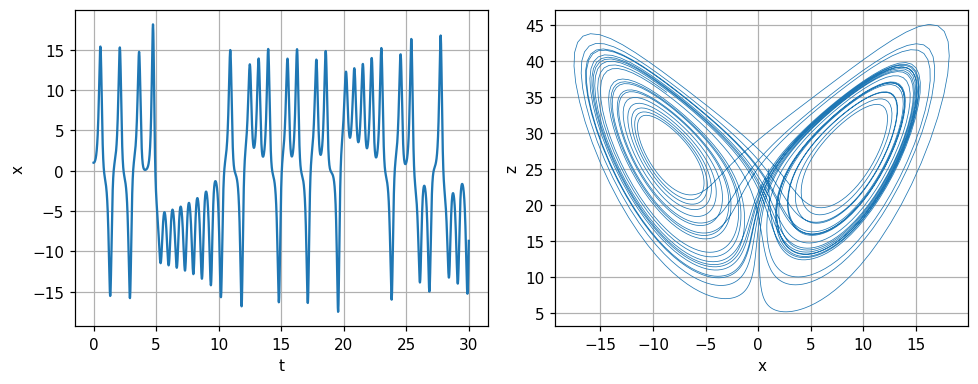

t =  0:  |difference| = 1.00e-06
t =  5:  |difference| = 1.55e-05
t = 10:  |difference| = 1.32e-03
t = 15:  |difference| = 4.01e-02


In [3]:
x0 = np.array([1.0, 1.0, 25.0])
X, _ = run(x0, 3000)
fig = plt.figure(figsize=(9, 3.6))
ax = fig.add_subplot(121); ax.plot(np.arange(3001)*h, X[:, 0]); ax.set_xlabel("t"); ax.set_ylabel("x")
ax = fig.add_subplot(122); ax.plot(X[:, 0], X[:, 2], lw=0.5); ax.set_xlabel("x"); ax.set_ylabel("z")
plt.tight_layout(); plt.show()

# sensitivity to initial conditions
Xa, _ = run(X[-1], 1500); Xb, _ = run(X[-1] + 1e-6*np.array([1, 0, 0]), 1500)
for t in [0, 5, 10, 15]:
    print(f"t = {t:2d}:  |difference| = {np.linalg.norm(Xa[int(t/h)] - Xb[int(t/h)]):.2e}")

A $10^{-6}$ perturbation grows about 40,000-fold in 15 time units and reaches order one around $t\approx25$: the signature of chaos.

## 2. The tangent-linear model

Perturb the initial state by $\delta\mathbf x_0$. To first order the perturbation evolves as

$$\delta\mathbf x_{k+1}=M_k\,\delta\mathbf x_k\quad\Rightarrow\quad \delta\mathbf x_N=M_{N-1}\cdots M_0\,\delta\mathbf x_0 .$$

This is the TLM: linear in $\delta\mathbf x$, but its matrices $M_k$ depend on the nonlinear trajectory. **Taylor test:** the nonlinear difference $\mathcal M(\mathbf x_0+\varepsilon\,\mathbf d)-\mathcal M(\mathbf x_0)$ divided by $\varepsilon$ should approach $\mathbf d\mapsto M_{N-1}\cdots M_0\mathbf d$ with an error that shrinks like $\varepsilon$.

In [4]:
def tlm(d, Ms):
    for M in Ms: d = M @ d
    return d

N = 100                                              # 1 time unit
xs = X[1000]                                         # a point on the attractor
Xref, Ms = run(xs, N)
d = np.array([0.3, -0.5, 0.8]); d /= np.linalg.norm(d)
print(f"{'eps':>9} {'|nonlinear/eps - TLM d|':>26}")
for eps in 10.0**-np.arange(1, 9):
    Xp, _ = run(xs + eps*d, N)
    err = np.linalg.norm((Xp[-1] - Xref[-1])/eps - tlm(d, Ms))
    print(f"{eps:9.0e} {err:26.3e}")

      eps    |nonlinear/eps - TLM d|
    1e-01                  1.217e-01
    1e-02                  1.193e-02
    1e-03                  1.190e-03
    1e-04                  1.190e-04
    1e-05                  1.190e-05
    1e-06                  1.176e-06
    1e-07                  4.326e-07
    1e-08                  8.165e-06


The error falls linearly with $\varepsilon$ until round-off takes over below $\varepsilon\approx10^{-7}$, so the TLM is the correct derivative of the discrete model.

## 3. The adjoint model

The TLM maps an initial perturbation to a final one: $\delta\mathbf x_N=\mathbf M\,\delta\mathbf x_0$ with $\mathbf M=M_{N-1}\cdots M_0$. The cost gradient needs the opposite: a sensitivity of a scalar $J$ at later times *back* to the initial state. By the chain rule it needs the **transpose**

$$\mathbf M^T=M_0^T\,M_1^T\cdots M_{N-1}^T ,$$

applied from the left: start at the last time and step backwards, multiplying by $M_k^T$. For the 4D-Var cost with observations at several times, each observation misfit is *injected* into the backward run when it is reached:

$$\boldsymbol\lambda_N=H^TR^{-1}(H\mathbf x_N-\mathbf y_N),\qquad \boldsymbol\lambda_k=M_k^T\boldsymbol\lambda_{k+1}+H^TR^{-1}(H\mathbf x_k-\mathbf y_k),\qquad \nabla_{\mathbf x_0}J=\boldsymbol\lambda_0+B^{-1}(\mathbf x_0-\mathbf x_b).$$

One forward run plus one backward run gives the whole gradient. The function below implements exactly this.

In [5]:
def cost_and_grad(x0, xb, Binv, Rinv, H, obs, obs_steps, nsteps):
    X, Ms = run(x0, nsteps)                          # forward run (stores the step matrices)
    dxb = x0 - xb
    J = 0.5 * dxb @ Binv @ dxb                       # background term
    forcing = {}
    for k, y in zip(obs_steps, obs):                 # observation terms
        r = H @ X[k] - y
        J += 0.5 * r @ Rinv @ r
        forcing[k] = H.T @ Rinv @ r                  # dJ/dx_k from this observation
    lam = forcing.get(nsteps, np.zeros_like(x0)).copy()
    for k in range(nsteps-1, -1, -1):                # adjoint run, backwards in time
        lam = Ms[k].T @ lam
        if k in forcing:
            lam = lam + forcing[k]
    return J, lam + Binv @ dxb

### Test 1: the dot-product test

For any vectors $\mathbf u,\mathbf v$: $\langle\mathbf M\mathbf u,\mathbf v\rangle=\langle\mathbf u,\mathbf M^T\mathbf v\rangle$. Unlike the others, this test needs no cost function and catches any error in the adjoint's coding, down to round-off.

In [6]:
def adjoint(v, Ms):
    for M in reversed(Ms): v = M.T @ v
    return v

rng = np.random.default_rng(0)
for N_ in [10, 100, 300]:
    _, Ms_ = run(xs, N_)
    u, v = rng.standard_normal(3), rng.standard_normal(3)
    lhs, rhs = np.dot(tlm(u, Ms_), v), np.dot(u, adjoint(v, Ms_))
    print(f"N = {N_:4d}:  <Mu,v> = {lhs: .10e}   <u,M^T v> = {rhs: .10e}   rel. diff = {abs(lhs-rhs)/abs(lhs):.1e}")

N =   10:  <Mu,v> = -1.0014542024e-01   <u,M^T v> = -1.0014542024e-01   rel. diff = 1.4e-16
N =  100:  <Mu,v> =  9.2832639124e-01   <u,M^T v> =  9.2832639124e-01   rel. diff = 7.5e-15
N =  300:  <Mu,v> = -1.7134802813e+01   <u,M^T v> = -1.7134802813e+01   rel. diff = 1.2e-14


### Test 2: gradient against finite differences

Set up a small assimilation problem (observe only $x$, every 0.25 time units, noise std 0.5) and compare the adjoint gradient of $J$ with central differences.

In [7]:
H = np.array([[1.0, 0.0, 0.0]])
sig_o, sig_b = 0.5, 1.0
Rinv, Binv = np.eye(1)/sig_o**2, np.eye(3)/sig_b**2

nsteps = 100
obs_steps = list(range(25, nsteps+1, 25))
Xt, _ = run(xs, nsteps)                                       # "truth"
rng = np.random.default_rng(1)
obs = [H @ Xt[k] + sig_o*rng.standard_normal(1) for k in obs_steps]
xb = xs + sig_b*rng.standard_normal(3)
x0 = xb + np.array([0.1, -0.2, 0.15])

J0, g = cost_and_grad(x0, xb, Binv, Rinv, H, obs, obs_steps, nsteps)
e = 1e-6
fd = np.array([(cost_and_grad(x0 + e*v, xb, Binv, Rinv, H, obs, obs_steps, nsteps)[0]
              - cost_and_grad(x0 - e*v, xb, Binv, Rinv, H, obs, obs_steps, nsteps)[0])/(2*e) for v in np.eye(3)])
print("J(x0)               :", J0)
print("adjoint gradient    :", g)
print("finite-diff gradient:", fd)
print("relative difference :", np.linalg.norm(g - fd)/np.linalg.norm(fd))

J(x0)               : 2.5933822172929233
adjoint gradient    : [ 2.74038828  0.48535624 -4.06038656]
finite-diff gradient: [ 2.74038827  0.48535624 -4.06038653]
relative difference : 6.767371053728393e-09


The gradient matches to about nine digits.

### Test 3: why bother? Cost scaling

Finite differences need $2n$ model runs for $n$ unknowns; the adjoint always needs one forward and one backward run. With three variables the difference is small. Let us measure it on a 40-variable system (the Lorenz-96 model, used in future tutorial).

In [8]:
import time
nL = 40; FL = 8.0
def f96(x):   return (np.roll(x,-1) - np.roll(x,2))*np.roll(x,1) - x + FL
def jac96(x):
    J = np.zeros((nL, nL)); i = np.arange(nL)
    J[i, (i+1) % nL] += np.roll(x, 1)
    J[i, (i-2) % nL] += -np.roll(x, 1)
    J[i, (i-1) % nL] += np.roll(x, -1) - np.roll(x, 2)
    J[i, i] += -1
    return J

# temporarily swap the model, reuse the same generic cost function
f_saved, jac_saved, h_saved = f, jac, h
f, jac, h = f96, jac96, 0.05
rng = np.random.default_rng(0)
xt = np.full(nL, FL); xt[0] += 0.01; xt = run(xt, 500)[0][-1]
H96 = np.eye(nL)[::2]; R96i = np.eye(20)
B96i = np.eye(nL)
ns = 6; steps = list(range(1, ns+1))
Xt96, _ = run(xt, ns)
obs96 = [H96 @ Xt96[k] + rng.standard_normal(20) for k in steps]
xb96 = xt + rng.standard_normal(nL); x96 = xb96.copy()

t0 = time.perf_counter(); J0, g96 = cost_and_grad(x96, xb96, B96i, R96i, H96, obs96, steps, ns); t_adj = time.perf_counter() - t0
t0 = time.perf_counter()
fd96 = np.array([(cost_and_grad(x96 + e*v, xb96, B96i, R96i, H96, obs96, steps, ns)[0]
                - cost_and_grad(x96 - e*v, xb96, B96i, R96i, H96, obs96, steps, ns)[0])/(2*e) for v in np.eye(nL)])
t_fd = time.perf_counter() - t0
print(f"adjoint: {t_adj*1e3:7.1f} ms     finite differences ({2*nL} runs): {t_fd*1e3:7.1f} ms     ratio: {t_fd/t_adj:.0f}x")
print("relative gradient difference:", np.linalg.norm(g96 - fd96)/np.linalg.norm(fd96))
f, jac, h = f_saved, jac_saved, h_saved               # restore Lorenz-63

adjoint:     3.0 ms     finite differences (80 runs):   228.2 ms     ratio: 76x
relative gradient difference: 1.1506579791069393e-09


The adjoint is about $2n$ times cheaper here (the measured ratio is close to the 80 runs finite differences need), and the ratio grows linearly with the number of unknowns. With $n=10^7$ (an operational weather model) finite differences are impossible and the adjoint is the only option, which is why operational centres maintain adjoint code for their models.

## Takeaways

- The **TLM** is the product of step Jacobians. The **adjoint** is the transposed product, run backwards, with observation misfits injected at their times.
- The adjoint of the *discrete* scheme gives the exact gradient of the computed cost. Always verify with the dot-product test and a finite-difference check.
- Cost: one forward plus one backward run, regardless of the number of unknowns.

## Exercises

1. Run the Taylor test with a larger $N$ (say 400 steps). At what $\varepsilon$ does the linear-error region begin? Link this to the chaotic growth rate.
2. Break the adjoint on purpose (use `M` instead of `M.T` in `cost_and_grad`) and observe which test catches it.
3. Store only the states, not the matrices $M_k$, and recompute the Jacobians inside the backward loop. What do you trade (memory against compute)? Operational systems use this "checkpointing" idea.
4. Rewrite the RK4 step in JAX and compare `jax.grad` of the cost with our adjoint gradient (compare with Tutorial 7). They should agree to round-off.